# Naïve Bayes for Spam Email Detection
Spam email is unsolicited and electronic email sent with the aim of advertisement or phishing. Spam emails are on the rise these days, and requires a modern solution.

Naïve Bayes is one of the most widely used machine-learning approaches to the problem. It operates on the principle that the probability of an email being spam depends on the conditional probabilities of multiple word tokens appearing in the email. The probability that is highest (either being spam or ham) tends to be the outcome.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import re
import nltk
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
nltk.download('stopwords')
nltk.download('all-corpora')

file_path = '/kaggle/input/datasets/karthickveerakumar/spam-filter/emails.csv'
df = pd.read_csv(file_path)

df.shape
print(df.head(10))
print(df.info())

[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading collection 'all-corpora'
[nltk_data]    | 
[nltk_data]    | Downloading package abc to /usr/share/nltk_data...
[nltk_data]    |   Package abc is already up-to-date!
[nltk_data]    | Downloading package alpino to /usr/share/nltk_data...
[nltk_data]    |   Package alpino is already up-to-date!
[nltk_data]    | Downloading package bcp47 to /usr/share/nltk_data...
[nltk_data]    | Downloading package biocreative_ppi to
[nltk_data]    |     /usr/share/nltk_data...
[nltk_data]    |   Package biocreative_ppi is already up-to-date!
[nltk_data]    | Downloading package brown to /usr/share/nltk_data...
[nltk_data]    |   Package brown is already up-to-date!
[nltk_data]    | Downloading package brown_tei to
[nltk_data]    |     /usr/share/nltk_data...
[nltk_data]    |   Package brown_tei is already up-to-date!
[nltk_data]    | Downloading package cess

                                                text  spam
0  Subject: naturally irresistible your corporate...     1
1  Subject: the stock trading gunslinger  fanny i...     1
2  Subject: unbelievable new homes made easy  im ...     1
3  Subject: 4 color printing special  request add...     1
4  Subject: do not have money , get software cds ...     1
5  Subject: great nnews  hello , welcome to medzo...     1
6  Subject: here ' s a hot play in motion  homela...     1
7  Subject: save your money buy getting this thin...     1
8  Subject: undeliverable : home based business f...     1
9  Subject: save your money buy getting this thin...     1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5728 entries, 0 to 5727
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    5728 non-null   object
 1   spam    5728 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 89.6+ KB
None


The dataset contains 2 columns and 5728 rows. No nulls reported, only data types include object and int64.

## Data Exploration
### Null & duplicate values

In [2]:
print(df.isnull().sum())
print('Duplicates:', df.duplicated().sum())

text    0
spam    0
dtype: int64
Duplicates: 33


There are no nulls in the dataset. However, 33 duplicates exist.

In [3]:
raw = df.copy()
df = raw.copy()

print(df.head())

                                                text  spam
0  Subject: naturally irresistible your corporate...     1
1  Subject: the stock trading gunslinger  fanny i...     1
2  Subject: unbelievable new homes made easy  im ...     1
3  Subject: 4 color printing special  request add...     1
4  Subject: do not have money , get software cds ...     1


Made a copy of the original dataset to preserve it.

In [4]:
df[df.duplicated(keep=False)].sort_values("text")

,text,spam
5716,Subject: * special notification * aurora versi...,0
3165,Subject: * special notification * aurora versi...,0
2473,"Subject: day off tuesday stinson , i would l...",0
1417,"Subject: day off tuesday stinson , i would l...",0
1801,Subject: departure of grant masson the resear...,0
...,...,...
3302,Subject: term project : this is the list of p...,0
3152,Subject: tiger evals - attachment tiger hosts...,0
2188,Subject: tiger evals - attachment tiger hosts...,0
4168,Subject: vp & director count for the research ...,0


The above output displays duplicate rows in the dataset. They do not provide any unique information to the dataset, and as such should be dropped.

In [5]:
df.drop_duplicates().reset_index(drop=True)

,text,spam
0,Subject: naturally irresistible your corporate...,1
1,Subject: the stock trading gunslinger fanny i...,1
2,Subject: unbelievable new homes made easy im ...,1
3,Subject: 4 color printing special request add...,1
4,"Subject: do not have money , get software cds ...",1
...,...,...
5690,Subject: re : research and development charges...,0
5691,"Subject: re : receipts from visit jim , than...",0
5692,Subject: re : enron case study update wow ! a...,0
5693,"Subject: re : interest david , please , call...",0


### Target Class imbalance

spam
0    4360
1    1368
Name: count, dtype: int64


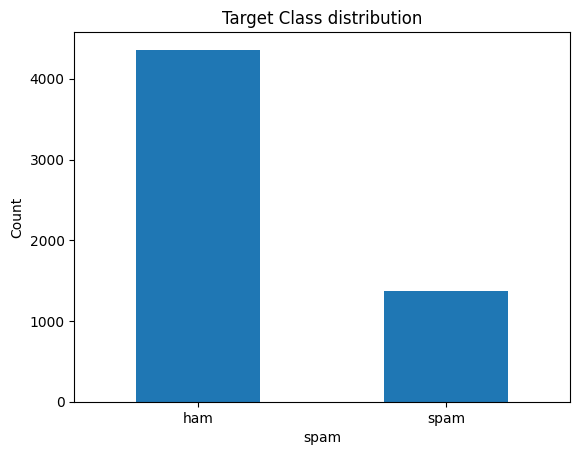

In [6]:
print(df['spam'].value_counts())
(df['spam'].value_counts(normalize=True))

df['spam'].value_counts().plot(kind='bar')
plt.xticks([0, 1], ['ham', 'spam'], rotation=0)
plt.ylabel('Count')
plt.title('Target Class distribution')
plt.show()

0 = ham, 1 = spam

Majority of the target constitutes ham (~ 76%). The classes are moderately imbalanced, so a model that always predicted "ham" would reach ~76% accuracy without detecting any spam. Accuracy alone is therefore misleading, and I'll evaluate with precision, recall, and F1 for the spam class.

### Exploration of target class

In [7]:
with pd.option_context("display.max_colwidth", None):
    print(df[df.spam == 0]["text"].sample(5))
    print(df[df.spam == 1]['text'].sample(5))

3445                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                    

**Ham (0):** Mostly internal business email: model reviews, hiring and interview logistics, data requests, short replies, and automated system messages (access approvals, mailing-list confirmations).

**Spam (1):** Promotional and scam content in several types: multi-level marketing, penny-stock promotion, advance-fee scams, pharmaceutical and pirated-software ads. Some messages include random filler text or raw email headers.

## Data Preprocessing